# 21. Chemical engineering: viscosity from a falling sphere

**Track:** core example &nbsp;·&nbsp; **Uses:** Chapters 1, 3 and 4

**Reading:** Taylor, ch. 3 · Happel & Brenner, *Low Reynolds Number
Hydrodynamics*

A small sphere falling slowly through a viscous liquid reaches a terminal
velocity at which its weight, the buoyancy and the Stokes drag balance.
Timing the fall between two marks gives the viscosity. The experiment is a
good model of a typical engineering measurement: one formula, half a dozen
inputs of very different quality, some measured (Type A) and some taken
from data sheets (Type B), and a correction for a non-ideal geometry.

The example shows how to

* build a Type B uncertainty from several pieces of information;
* set up a complete uncertainty budget and read it;
* recognise that a known systematic effect can exceed the whole random
  budget many times over;
* include a *model* uncertainty as an explicit input;
* state what the final uncertainty does and does not cover.

The data are simulated. The liquid is given a viscosity of 1.200 Pa s
(typical of glycerol slightly above 20 °C).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(22)

## The measurement model

For a sphere of diameter $d$ and density $\rho_\mathrm{s}$ falling at
terminal velocity $v$ in an unbounded liquid of density $\rho_\mathrm{f}$
and viscosity $\eta$, the force balance at low Reynolds number is

$$ \underbrace{3\pi\eta\,d\,v}_{\text{Stokes drag}} = \underbrace{\tfrac{\pi}{6}d^3(\rho_\mathrm{s}-\rho_\mathrm{f})\,g}_{\text{weight minus buoyancy}}
   \qquad\Longrightarrow\qquad
   \eta = \frac{d^2(\rho_\mathrm{s}-\rho_\mathrm{f})\,g}{18\,v} . $$

With $v = L/t$ for a fall of distance $L$ in time $t$,

$$ \eta_\text{Stokes} = \frac{d^2(\rho_\mathrm{s}-\rho_\mathrm{f})\,g\,t}{18\,L} . $$

## The inputs and their uncertainties

| Quantity | How obtained | Value | Standard uncertainty | Type |
|---|---|---|---|---|
| fall time $t$ | 8 drops, stopwatch | see below | standard error | A |
| ball diameter $d$ | micrometer | 2.000 mm | 0.004 mm | B |
| fall distance $L$ | two marks on the tube, ruler | 200.0 mm | 0.5 mm | B |
| ball density $\rho_\mathrm{s}$ | data sheet for the steel | 7800 kg/m³ | 30 kg/m³ | B |
| liquid density $\rho_\mathrm{f}$ | pycnometer | 1260 kg/m³ | 2 kg/m³ | B |
| gravity $g$ | local value | 9.810 m/s² | 0.005 m/s² | B |
| tube inner diameter $D$ | calliper | 40.0 mm | 0.2 mm | B |

### Building a Type B uncertainty: the ball diameter

Three pieces of information are available about the diameter, and none of
them is a standard deviation. Each is converted with the rules of
Section 1.3 and the results are combined in quadrature.

In [2]:
u_resolution = 0.001 / np.sqrt(12)      # micrometer reads to 0.001 mm
u_accuracy = 0.004 / np.sqrt(3)         # maker: "accuracy +/- 0.004 mm", taken as rectangular
u_roundness = 0.005 / np.sqrt(3)        # ball grade: diameter variation within +/- 0.005 mm
u_d_mm = np.sqrt(u_resolution**2 + u_accuracy**2 + u_roundness**2)
print(f"resolution {u_resolution:.4f} mm, accuracy {u_accuracy:.4f} mm, roundness {u_roundness:.4f} mm")
print(f"combined standard uncertainty of d: {u_d_mm:.4f} mm  ->  use 0.004 mm")

resolution 0.0003 mm, accuracy 0.0023 mm, roundness 0.0029 mm
combined standard uncertainty of d: 0.0037 mm  ->  use 0.004 mm


The resolution, the first thing one thinks of, is negligible. The fall
distance is treated similarly: each mark is located to within ±0.5 mm
(rectangular, 0.29 mm), two marks give 0.41 mm, and a little is added for
parallax, giving 0.5 mm.

### The simulated measurement

Skip the next cell on first reading. It creates one laboratory's
experiment: every instrument has an error drawn from its uncertainty and
fixed for the whole experiment, so the actual dimensions differ slightly
from the readings in the table, and the fall times scatter from drop to
drop.

In [3]:
# ---- the simulated experiment ------------------------------------------------
eta_true = 1.200                                                  # Pa s (hidden)
names = ["d", "L", "rho_s", "rho_f", "g", "D"]
meas = dict(d=2.000e-3, L=0.2000, rho_s=7800.0, rho_f=1260.0, g=9.810, D=40.0e-3)   # the readings
unc = dict(d=0.004e-3, L=0.5e-3, rho_s=30.0, rho_f=2.0, g=0.005, D=0.2e-3)
sigma_t, n_drops = 0.15, 8

def faxen(lam):
    """Ratio of the fall velocity on the axis of a tube to that in an unbounded liquid."""
    return 1 - 2.104 * lam + 2.09 * lam**3 - 0.95 * lam**5

def fall_time(eta, d, L, rho_s, rho_f, g, D):
    v_unbounded = d**2 * (rho_s - rho_f) * g / (18 * eta)
    return L / (v_unbounded * faxen(d / D))

# hidden: the actual dimensions and densities differ from the readings by one
# fixed error per instrument, drawn from its stated uncertainty
actual = {k: meas[k] - rng.normal(0, unc[k]) for k in names}
t_drops = np.round(fall_time(eta_true, **actual) + rng.normal(0, sigma_t, n_drops), 2)
print("fall times (s):", t_drops)

fall times (s): [18.8  18.84 18.6  18.55 18.72 18.84 18.98 18.79]


## Step 1. The fall time (Type A)

In [4]:
t_mean, s_t, u_t = ep.mean_sem(t_drops)
print(f"mean {t_mean:.3f} s, standard deviation {s_t:.3f} s, standard error {u_t:.3f} s ({u_t / t_mean:.2%})")

mean 18.765 s, standard deviation 0.139 s, standard error 0.049 s (0.26%)


## Step 2. Stokes' formula and its budget

In [5]:
def eta_stokes(t, d, L, rho_s, rho_f, g):
    return d**2 * (rho_s - rho_f) * g * t / (18 * L)

x1 = [t_mean] + [meas[k] for k in names[:5]]
u1 = [u_t] + [unc[k] for k in names[:5]]
rows1, eta1, u_eta1 = ep.budget(eta_stokes, x1, u1, names=["t"] + names[:5])
print(ep.format_budget(rows1, eta1, u_eta1))
print("\neta (Stokes) =", ep.format_result(eta1, u_eta1, "Pa s"))

input             value           u    rel. u        |c| u    share
-------------------------------------------------------------------
t                18.765       0.049     0.26%       0.0035    13.5%
d                 0.002       4e-06     0.20%      0.00535    31.7%
L                   0.2      0.0005     0.25%      0.00334    12.4%
rho_s              7800          30     0.38%      0.00614    41.7%
rho_f              1260           2     0.16%     0.000409     0.2%
g                  9.81       0.005     0.05%     0.000682     0.5%
-------------------------------------------------------------------
output           1.3377      0.0095     0.71%

eta (Stokes) = 1.3377 ± 0.0095 Pa s


The budget is reasonably balanced. The ball density and diameter lead,
time and distance follow, and the total is below 1 %. It looks like a
careful measurement.

Is it right? In a real laboratory one would compare with a reference
liquid. Here we can look at the truth: the liquid has
$\eta = 1.200$ Pa s.

In [6]:
print(f"Stokes result {eta1:.3f} Pa s, true value {eta_true:.3f} Pa s: "
      f"error {eta1 / eta_true - 1:+.1%}, that is {abs(eta1 - eta_true) / u_eta1:.0f} standard uncertainties")

Stokes result 1.338 Pa s, true value 1.200 Pa s: error +11.5%, that is 14 standard uncertainties


The result is wrong by 11.5 %, fourteen times its stated uncertainty. Nothing in the budget is at fault. The *formula* is.

## Step 3. The wall correction

Stokes' law assumes an unbounded liquid. In a tube, the liquid displaced
by the ball has to flow back through the gap between ball and wall, which
increases the drag and slows the fall. For a sphere on the axis of a tube
of diameter $D$, the velocity is reduced by Faxén's factor

$$ \frac{v}{v_\infty} = f(\lambda) = 1 - 2.104\,\lambda + 2.09\,\lambda^3 - 0.95\,\lambda^5 , \qquad \lambda = \frac{d}{D} , $$

so that

$$ \eta = \eta_\text{Stokes}\,f(\lambda) . $$

The correction is linear in $\lambda$ and therefore surprisingly large: a
2 mm ball in a 40 mm tube has $\lambda = 0.05$, a twentieth of the tube
diameter, and falls more than 10 % slower than in an unbounded liquid.

### A model uncertainty as an explicit input

Faxén's formula is itself an idealisation. The ball is not released
exactly on the axis, and the tube has a bottom and a free surface. We
judge that the *correction* (not the viscosity) is good to about 5 % of
itself, which is 0.5 % of $\eta$, and represent this by a factor
$c = 1.000 \pm 0.005$ multiplying the result. The factor does not change
the value. It makes the judgement visible in the budget, where a reader
can see it and replace it by a better one.

In [7]:
def eta_corrected(t, d, L, rho_s, rho_f, g, D, c):
    return c * eta_stokes(t, d, L, rho_s, rho_f, g) * faxen(d / D)

x2 = x1 + [meas["D"], 1.0]
u2 = u1 + [unc["D"], 0.005]
labels = ["t", "d", "L", "rho_s", "rho_f", "g", "D", "c (model)"]
rows2, eta2, u_eta2 = ep.budget(eta_corrected, x2, u2, names=labels)
print(ep.format_budget(rows2, eta2, u_eta2))
print(f"\nwall factor f = {faxen(meas['d'] / meas['D']):.4f}")
print("eta (corrected) =", ep.format_result(eta2, u_eta2, "Pa s"))
print(f"deviation from the true value: {abs(eta2 - eta_true) / u_eta2:.1f} standard uncertainties")

input             value           u    rel. u        |c| u    share
-------------------------------------------------------------------
t                18.765       0.049     0.26%      0.00313     9.2%
d                 0.002       4e-06     0.20%      0.00451    19.2%
L                   0.2      0.0005     0.25%      0.00299     8.4%
rho_s              7800          30     0.38%      0.00549    28.4%
rho_f              1260           2     0.16%     0.000366     0.1%
g                  9.81       0.005     0.05%      0.00061     0.4%
D                  0.04      0.0002     0.50%     0.000698     0.5%
c (model)             1       0.005     0.50%      0.00599    33.8%
-------------------------------------------------------------------
output           1.1973        0.01     0.86%

wall factor f = 0.8951
eta (corrected) = 1.197 ± 0.010 Pa s
deviation from the true value: 0.3 standard uncertainties


With the correction, the result agrees with the true value within its
uncertainty. The budget has changed in an instructive way:

* the tube diameter enters only through the correction, and although it is
  known to just 0.5 %, it contributes almost nothing, because the
  correction is a 10 % effect and $0.5\,\% \times 10\,\% = 0.05\,\%$;
* the model uncertainty of the correction is now one of the largest
  entries;
* the sensitivity to $d$ has changed slightly, because $d$ now also
  appears in $\lambda$.

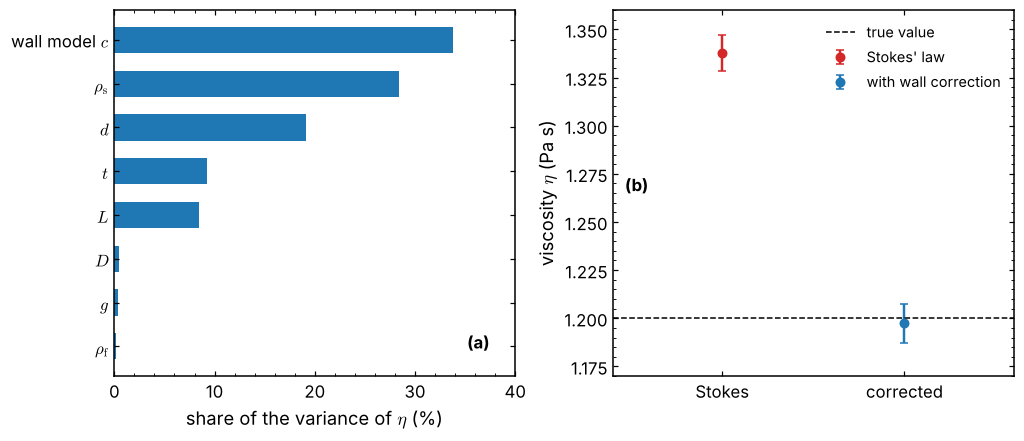

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.9))

ax = axes[0]
share = np.array([r["variance_fraction"] for r in rows2]) * 100
order = np.argsort(share)
tex = {"t": "$t$", "d": "$d$", "L": "$L$", "rho_s": r"$\rho_\mathrm{s}$", "rho_f": r"$\rho_\mathrm{f}$",
       "g": "$g$", "D": "$D$", "c (model)": "wall model $c$"}
ax.barh([tex[labels[i]] for i in order], share[order], color="C0", height=0.6)
ax.set_xlabel(r"share of the variance of $\eta$ (%)")
ax.tick_params(axis="y", which="minor", left=False, right=False)
ax.set_xlim(0, 40); ep.panel_label(ax, "(a)", x=0.88, y=0.12)

ax = axes[1]
ax.errorbar([0], [eta1], yerr=[u_eta1], fmt="o", color="C3", label="Stokes' law")
ax.errorbar([1], [eta2], yerr=[u_eta2], fmt="o", color="C0", label="with wall correction")
ax.axhline(eta_true, color="k", ls="--", lw=1, label="true value")
ax.set_xlim(-0.6, 1.6); ax.set_xticks([0, 1]); ax.set_xticklabels(["Stokes", "corrected"])
ax.tick_params(axis="x", which="minor", bottom=False, top=False)
ax.set_ylabel(r"viscosity $\eta$ (Pa s)"); ax.set_ylim(1.17, 1.36); ax.legend(loc="upper right"); ep.panel_label(ax, "(b)", y=0.55)
plt.show()

## Step 4. Testing the budget on many laboratories

A Type B error is a fixed number in any one laboratory: this micrometer
reads 0.003 mm high today and tomorrow. In what sense, then, is its
uncertainty a standard deviation? Imagine many laboratories doing the same
experiment, each with its own micrometer, ruler, steel and tube. Over this
ensemble the instrument errors scatter with the stated uncertainties, and
a correct budget predicts the scatter of the final results. On a computer
we can run the ensemble.

In [9]:
n_lab = 20_000
# every laboratory has the same actual apparatus (the table values) and its own instrument errors
M = {k: meas[k] + rng.normal(0, unc[k], n_lab) for k in names}       # each lab's readings
t_lab = fall_time(eta_true, **meas) + rng.normal(0, sigma_t / np.sqrt(n_drops), n_lab)
eta_lab = eta_corrected(t_lab, M["d"], M["L"], M["rho_s"], M["rho_f"], M["g"], M["D"], 1.0)

print(f"scatter of eta over {n_lab} simulated laboratories: {eta_lab.std(ddof=1) / eta_true:.3%}")
print(f"budget without the model term                     : "
      f"{np.sqrt(u_eta2**2 - (0.005 * eta2)**2) / eta2:.3%}")
print(f"budget with the model term                        : {u_eta2 / eta2:.3%}")
print(f"mean over laboratories / true value - 1           : {eta_lab.mean() / eta_true - 1:+.4%}")

scatter of eta over 20000 simulated laboratories: 0.710%
budget without the model term                     : 0.700%
budget with the model term                        : 0.860%
mean over laboratories / true value - 1           : +0.0109%


The scatter between laboratories reproduces the budget without the model
term, as it should: in the simulation Faxén's formula is exact, so that
term has nothing to cover. In reality it is the allowance for our
ignorance of how good the formula is, and no simulation built on the same
formula can test it.

## Step 5. What the uncertainty does not cover

The final statement is "$\eta = \dots$ Pa s with a relative standard
uncertainty of about 0.9 %". It is a statement about the viscosity of the
liquid *in the tube, at whatever temperature it had*.

The viscosity of glycerol is extremely sensitive to temperature: handbook
values fall from about 1.41 Pa s at 20 °C to about 0.61 Pa s at 30 °C,
which is roughly 8 % per kelvin. If the result is to be reported as "the
viscosity at 22.0 °C", the uncertainty of the temperature enters. With a
thermometer good to 0.3 K,

$$ \frac{u_\eta}{\eta}\bigg|_\text{temperature} \approx 0.08\ \mathrm{K^{-1}} \times 0.3\ \mathrm{K} = 2.4\,\% , $$

which is larger than everything else in the budget combined. A further
source of the same kind is water content, since glycerol is hygroscopic
and a per cent of absorbed water lowers its viscosity by a comparable
amount.

This is the most general lesson of the example. An uncertainty budget
answers the question that the measurement model poses. Whether that is the
question the user of the number is asking has to be checked separately.

## Summary

* Type B uncertainties are assembled from tolerances, data sheets and
  judgement, converted to standard deviations and combined in quadrature.
* A balanced budget below 1 % did not prevent an 11.5 % error: the model was
  incomplete. Budgets quantify the uncertainty of the inputs, not the
  validity of the formula.
* Corrections should be applied, and their own uncertainty, including that
  of the correction formula, entered in the budget.
* A large correction makes a result insensitive to the *inputs* of the
  correction only if the correction is a small fraction of the result.
* Define the measurand completely (which liquid, at which temperature)
  before claiming an uncertainty for it.

## References

* J. Happel and H. Brenner, *Low Reynolds Number Hydrodynamics* (Prentice-Hall,
  1965), for Faxén's wall correction to Stokes' law.

## Exercises

1. Which single improvement to the apparatus would reduce the combined
   uncertainty most? By how much?
2. Use a 1 mm ball instead (same absolute uncertainty of the diameter). How
   do the wall correction and the budget change? What is the trade-off?
3. The Reynolds number of the fall is $Re = \rho_\mathrm{f}vd/\eta$.
   Compute it. The first inertial correction to Stokes' drag in an
   unbounded liquid is the factor $1 + \tfrac{3}{16}Re$ (Oseen). Should it
   be in the budget?
4. Propagate the corrected model with `ep.monte_carlo`, taking rectangular
   distributions for the Type B inputs. Does the result differ from the
   linear budget?
5. Replace the temperature argument of Step 5 by a calculation: add the
   temperature as an input of the model with an Arrhenius-type dependence
   $\eta \propto e^{B/T}$ fitted to the two handbook values.

---

**Previous:** [20. Physics: the acceleration of gravity from a pendulum](20_pendulum_g.ipynb) &nbsp;·&nbsp; **Next:** [22. Chemistry: activation energy from an Arrhenius plot](22_arrhenius_activation_energy.ipynb)